In [ ]:
import polars as pl
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd().parent        
book = pl.read_parquet(ROOT / "data" / "processed" / "book_states.parquet")
trades = pl.read_parquet(ROOT / "data" / "processed" / "trades.parquet")
print(book.shape, trades.shape)
book.head()

(7451501, 11) (39096, 10)


timestamp,bid_prices,bid_sizes,ask_prices,ask_sizes,ofi,symbol,session,mid,spread,dmid
"datetime[μs, UTC]",f64,i64,f64,i64,i64,str,str,f64,f64,f64
2026-09-11 12:00:01.118533 UTC,762.28,100,null,null,null,"""SPY""","""pre""",null,null,null
2026-09-11 12:00:01.118620 UTC,762.28,100,762.41,100,null,"""SPY""","""pre""",762.345,0.13,null
2026-09-11 12:00:01.369084 UTC,762.31,100,762.41,100,100,"""SPY""","""pre""",762.36,0.1,0.015
2026-09-11 12:00:01.517991 UTC,762.28,100,762.41,100,-100,"""SPY""","""pre""",762.345,0.13,-0.015
2026-09-11 12:00:01.628174 UTC,762.31,100,762.41,100,100,"""SPY""","""pre""",762.36,0.1,0.015


share of exactly zero: 0.21756358967113817
1%, 50%, 99%, 99.9% percentiles: [-200.0, 0.0, 200.0, 1500.0]


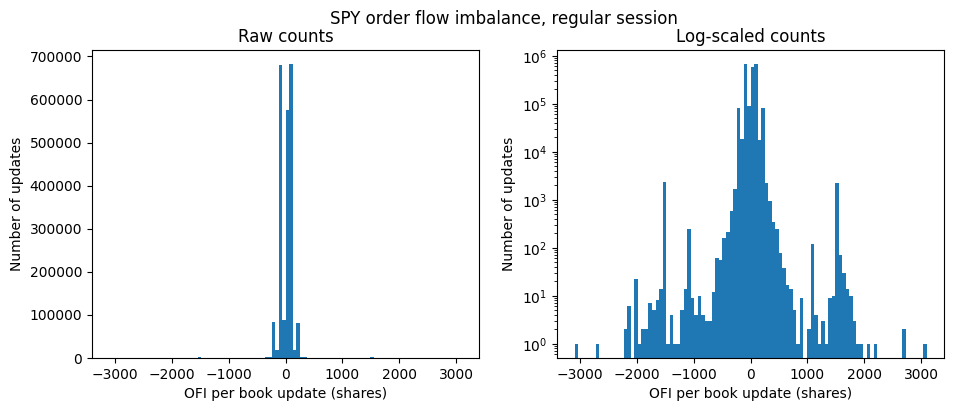

In [2]:
(ROOT / "figures").mkdir(exist_ok=True)

spy = (book.filter((pl.col("symbol") == "SPY") & (pl.col("session") == "regular"))
           .drop_nulls("ofi"))
ofi = spy["ofi"].to_numpy()
print("share of exactly zero:", (ofi == 0).mean())
print("1%, 50%, 99%, 99.9% percentiles:", [float(x) for x in
      __import__("numpy").percentile(ofi, [1, 50, 99, 99.9])])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(ofi, bins=100)
ax[0].set_title("Raw counts")
ax[1].hist(ofi, bins=100)
ax[1].set_yscale("log")
ax[1].set_title("Log-scaled counts")
for a in ax:
    a.set_xlabel("OFI per book update (shares)")
    a.set_ylabel("Number of updates")
fig.suptitle("SPY order flow imbalance, regular session")
fig.savefig(ROOT / "figures" / "01_spy_ofi_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

windows: 23340 | rank corr: 0.5919579131734685
OFI  min/max: -31568 12606 | plot edges: -3896.525 3736.100000000006
dmid min/max: -0.7800000000000864 11.80499999999995 | plot edges: -0.24652500000000313 0.2599999999999909
share outside plot box: 0.01979434447300771


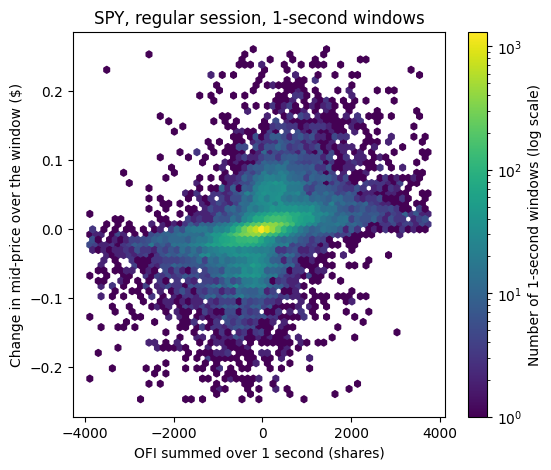

In [5]:
import numpy as np

w = (book.filter((pl.col("symbol") == "SPY") & (pl.col("session") == "regular"))
         .sort("timestamp")
         .group_by_dynamic("timestamp", every="1s")
         .agg(pl.col("ofi").sum().alias("ofi_sum"), pl.col("mid").last().alias("mid_end"))
         .with_columns(pl.col("mid_end").diff().alias("dmid_w"))
         .drop_nulls(["ofi_sum", "dmid_w"]))

x, y = w["ofi_sum"].to_numpy(), w["dmid_w"].to_numpy()
print("windows:", len(w), "| rank corr:", w.select(pl.corr("ofi_sum", "dmid_w", method="spearman")).item())

lx, hx = np.percentile(x, [0.5, 99.5]); ly, hy = np.percentile(y, [0.5, 99.5])
print("OFI  min/max:", x.min(), x.max(), "| plot edges:", lx, hx)
print("dmid min/max:", y.min(), y.max(), "| plot edges:", ly, hy)
print("share outside plot box:", ((x < lx) | (x > hx) | (y < ly) | (y > hy)).mean())
fig, ax = plt.subplots(figsize=(6, 5))
hb = ax.hexbin(x, y, gridsize=60, bins="log", extent=(lx, hx, ly, hy), mincnt=1)
fig.colorbar(hb, label="Number of 1-second windows (log scale)")
ax.set_xlabel("OFI summed over 1 second (shares)")
ax.set_ylabel("Change in mid-price over the window ($)")
ax.set_title("SPY, regular session, 1-second windows")
fig.savefig(ROOT / "figures" / "02_spy_ofi_vs_dmid_1s.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
from scipy.stats import theilslopes

rng = np.random.default_rng(42)
idx = rng.choice(len(x), size=5000, replace=False)

slope, intercept, lo, hi = theilslopes(y[idx], x[idx])
print("slope:", slope, "| 95% range:", lo, hi)
print("intercept:", intercept)
print("per 1,000 shares of OFI: $", slope * 1000)

slope: 2.0779220779260937e-05 | 95% range: 1.9823788546337642e-05 2.1739130434762837e-05
intercept: 0.00010389610389630468
per 1,000 shares of OFI: $ 0.020779220779260938


In [8]:
pl.Config.set_tbl_cols(10)

i_big = int(w["dmid_w"].arg_max())
print("Largest mid-price jump, with 2 rows before and after:")
print(w.slice(max(i_big - 2, 0), 5))

i_low = int(w["ofi_sum"].arg_min())
print("\nMost negative OFI, with 2 rows before and after:")
print(w.slice(max(i_low - 2, 0), 5))

Largest mid-price jump, with 2 rows before and after:
shape: (3, 4)
┌─────────────────────────┬─────────┬─────────┬────────┐
│ timestamp               ┆ ofi_sum ┆ mid_end ┆ dmid_w │
│ ---                     ┆ ---     ┆ ---     ┆ ---    │
│ datetime[μs, UTC]       ┆ i64     ┆ f64     ┆ f64    │
╞═════════════════════════╪═════════╪═════════╪════════╡
│ 2026-09-11 19:59:57 UTC ┆ -31568  ┆ 764.105 ┆ -0.105 │
│ 2026-09-11 19:59:58 UTC ┆ -13878  ┆ 764.14  ┆ 0.035  │
│ 2026-09-11 19:59:59 UTC ┆ 2263    ┆ 775.945 ┆ 11.805 │
└─────────────────────────┴─────────┴─────────┴────────┘

Most negative OFI, with 2 rows before and after:
shape: (5, 4)
┌─────────────────────────┬─────────┬─────────┬────────┐
│ timestamp               ┆ ofi_sum ┆ mid_end ┆ dmid_w │
│ ---                     ┆ ---     ┆ ---     ┆ ---    │
│ datetime[μs, UTC]       ┆ i64     ┆ f64     ┆ f64    │
╞═════════════════════════╪═════════╪═════════╪════════╡
│ 2026-09-11 19:59:55 UTC ┆ -4303   ┆ 764.325 ┆ 0.0    │
│ 2026-09-11 

In [9]:
from datetime import timedelta

t = w["timestamp"][i_big]
raw = (book.filter((pl.col("symbol") == "SPY")
                   & (pl.col("timestamp") >= t)
                   & (pl.col("timestamp") < t + timedelta(seconds=1)))
           .select("timestamp", "ofi", "mid", "spread"))
print(len(raw), "book states in that second")
print(raw.head(30))

767 book states in that second
shape: (30, 4)
┌────────────────────────────────┬──────┬─────────┬────────┐
│ timestamp                      ┆ ofi  ┆ mid     ┆ spread │
│ ---                            ┆ ---  ┆ ---     ┆ ---    │
│ datetime[μs, UTC]              ┆ i64  ┆ f64     ┆ f64    │
╞════════════════════════════════╪══════╪═════════╪════════╡
│ 2026-09-11 19:59:59.004994 UTC ┆ 65   ┆ 764.145 ┆ 0.03   │
│ 2026-09-11 19:59:59.005016 UTC ┆ 0    ┆ 764.145 ┆ 0.03   │
│ 2026-09-11 19:59:59.005246 UTC ┆ 100  ┆ 764.145 ┆ 0.03   │
│ 2026-09-11 19:59:59.005311 UTC ┆ -100 ┆ 764.145 ┆ 0.03   │
│ 2026-09-11 19:59:59.005530 UTC ┆ 0    ┆ 764.145 ┆ 0.03   │
│ …                              ┆ …    ┆ …       ┆ …      │
│ 2026-09-11 19:59:59.016957 UTC ┆ 65   ┆ 764.25  ┆ 0.2    │
│ 2026-09-11 19:59:59.017443 UTC ┆ 200  ┆ 764.25  ┆ 0.2    │
│ 2026-09-11 19:59:59.019351 UTC ┆ -200 ┆ 764.25  ┆ 0.2    │
│ 2026-09-11 19:59:59.019790 UTC ┆ 100  ┆ 764.25  ┆ 0.2    │
│ 2026-09-11 19:59:59.019836 UTC ┆ 200 

In [10]:
pl.Config.set_tbl_rows(20)
print(raw.tail(10))
print(raw.select(pl.col("mid").max(), pl.col("spread").max()))
print(raw.filter(pl.col("mid") > 770).head(5))

shape: (10, 4)
┌────────────────────────────────┬───────┬─────────┬────────┐
│ timestamp                      ┆ ofi   ┆ mid     ┆ spread │
│ ---                            ┆ ---   ┆ ---     ┆ ---    │
│ datetime[μs, UTC]              ┆ i64   ┆ f64     ┆ f64    │
╞════════════════════════════════╪═══════╪═════════╪════════╡
│ 2026-09-11 19:59:59.991511 UTC ┆ 100   ┆ 764.185 ┆ 0.03   │
│ 2026-09-11 19:59:59.991645 UTC ┆ 200   ┆ 764.27  ┆ 0.2    │
│ 2026-09-11 19:59:59.991891 UTC ┆ -100  ┆ 764.26  ┆ 0.22   │
│ 2026-09-11 19:59:59.992074 UTC ┆ 1080  ┆ 764.265 ┆ 0.23   │
│ 2026-09-11 19:59:59.993092 UTC ┆ 1080  ┆ 764.27  ┆ 0.24   │
│ 2026-09-11 19:59:59.995128 UTC ┆ -1080 ┆ 764.265 ┆ 0.25   │
│ 2026-09-11 19:59:59.996154 UTC ┆ 1080  ┆ 764.27  ┆ 0.26   │
│ 2026-09-11 19:59:59.997168 UTC ┆ -1080 ┆ 764.265 ┆ 0.27   │
│ 2026-09-11 19:59:59.998188 UTC ┆ 1080  ┆ 775.95  ┆ 23.64  │
│ 2026-09-11 19:59:59.999208 UTC ┆ -1080 ┆ 775.945 ┆ 23.65  │
└────────────────────────────────┴───────┴─────────┴───

In [11]:
w_ny = w.with_columns(pl.col("timestamp").dt.convert_time_zone("America/New_York").alias("ny"))
print(w_ny.sort(pl.col("dmid_w").abs(), descending=True).select("ny", "ofi_sum", "dmid_w").head(10))
print(w_ny.sort(pl.col("ofi_sum").abs(), descending=True).select("ny", "ofi_sum", "dmid_w").head(10))

shape: (10, 3)
┌────────────────────────────────┬─────────┬────────┐
│ ny                             ┆ ofi_sum ┆ dmid_w │
│ ---                            ┆ ---     ┆ ---    │
│ datetime[μs, America/New_York] ┆ i64     ┆ f64    │
╞════════════════════════════════╪═════════╪════════╡
│ 2026-09-11 15:59:59 EDT        ┆ 2263    ┆ 11.805 │
│ 2026-09-11 09:40:36 EDT        ┆ 11043   ┆ 1.115  │
│ 2026-09-11 09:30:56 EDT        ┆ 1305    ┆ 0.8    │
│ 2026-09-11 09:31:45 EDT        ┆ -1575   ┆ -0.78  │
│ 2026-09-11 09:33:45 EDT        ┆ -560    ┆ -0.78  │
│ 2026-09-11 09:30:13 EDT        ┆ -1675   ┆ 0.755  │
│ 2026-09-11 09:33:22 EDT        ┆ -422    ┆ -0.735 │
│ 2026-09-11 09:33:41 EDT        ┆ -1120   ┆ -0.725 │
│ 2026-09-11 09:31:35 EDT        ┆ -190    ┆ -0.715 │
│ 2026-09-11 09:34:19 EDT        ┆ -1550   ┆ -0.715 │
└────────────────────────────────┴─────────┴────────┘
shape: (10, 3)
┌────────────────────────────────┬─────────┬────────┐
│ ny                             ┆ ofi_sum ┆ dmid_w 

In [ ]:
#trim and refit
#Decision: drop the final minute (from 15:59:00 onward) from the 1-second analysis. This removes 60 of 23,340 windows (0.26%)

In [14]:
before_cut = (pl.col("ny").dt.hour() < 15) | ((pl.col("ny").dt.hour() == 15) & (pl.col("ny").dt.minute() < 59))

w_trim = (w.with_columns(pl.col("timestamp").dt.convert_time_zone("America/New_York").alias("ny"))
           .filter(before_cut))
x2, y2 = w_trim["ofi_sum"].to_numpy(), w_trim["dmid_w"].to_numpy()

print("windows before / after trim:", len(w), len(w_trim))
print("OFI  min/max:", x2.min(), x2.max())
print("dmid min/max:", y2.min(), y2.max())
print("rank corr after trim:", w_trim.select(pl.corr("ofi_sum", "dmid_w", method="spearman")).item())

rng = np.random.default_rng(42)
idx2 = rng.choice(len(x2), size=5000, replace=False)
s2, i2, lo2, hi2 = theilslopes(y2[idx2], x2[idx2])
print("slope after trim:", s2, "| 95% range:", lo2, hi2, "| intercept:", i2)
print("slope before trim: 2.078e-05")

windows before / after trim: 23340 23280
OFI  min/max: -20530 12606
dmid min/max: -0.7800000000000864 1.115000000000009
rank corr after trim: 0.5918607996435273
slope after trim: 2.0895522388040698e-05 | 95% range: 1.9973368841677822e-05 2.1897810218958186e-05 | intercept: 0.0
slope before trim: 2.078e-05


In [ ]:
#what are the ±1,100 clusters?

In [17]:
spy = book.filter((pl.col("symbol") == "SPY") & (pl.col("session") == "regular"))
# odd = spy.filter(pl.col("ofi").abs().is_between(1050, 1120))
odd = spy.filter(pl.col("ofi").abs().is_between(1450, 1550))
print(odd["ofi"].value_counts(sort=True).head(8))

hrs = odd.with_columns(pl.col("timestamp").dt.convert_time_zone("America/New_York").dt.hour().alias("hour"))
print(hrs["hour"].value_counts().sort("hour"))

shape: (8, 2)
┌───────┬───────┐
│ ofi   ┆ count │
│ ---   ┆ ---   │
│ i64   ┆ u32   │
╞═══════╪═══════╡
│ -1500 ┆ 2285  │
│ 1500  ┆ 2229  │
│ 1540  ┆ 9     │
│ -1540 ┆ 2     │
│ 1495  ┆ 2     │
│ 1499  ┆ 2     │
│ 1480  ┆ 2     │
│ 1497  ┆ 2     │
└───────┴───────┘
shape: (3, 2)
┌──────┬───────┐
│ hour ┆ count │
│ ---  ┆ ---   │
│ i8   ┆ u32   │
╞══════╪═══════╡
│ 11   ┆ 17    │
│ 14   ┆ 518   │
│ 15   ┆ 4014  │
└──────┴───────┘


In [18]:
#redo Plot 2 with the trimmed data and the fitted line

share outside plot box: 0.019759450171821305


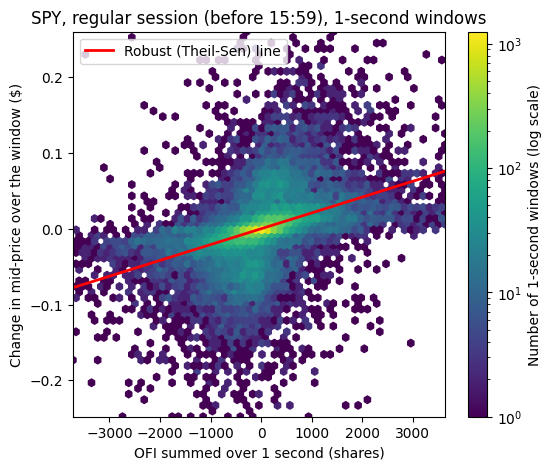

In [19]:
lx, hx = np.percentile(x2, [0.5, 99.5]); ly, hy = np.percentile(y2, [0.5, 99.5])
print("share outside plot box:", ((x2 < lx) | (x2 > hx) | (y2 < ly) | (y2 > hy)).mean())

fig, ax = plt.subplots(figsize=(6, 5))
hb = ax.hexbin(x2, y2, gridsize=60, bins="log", extent=(lx, hx, ly, hy), mincnt=1)
fig.colorbar(hb, label="Number of 1-second windows (log scale)")
xs = np.array([lx, hx])
ax.plot(xs, s2 * xs + i2, color="red", lw=2, label="Robust (Theil-Sen) line")
ax.set_xlim(lx, hx); ax.set_ylim(ly, hy)
ax.set_xlabel("OFI summed over 1 second (shares)")
ax.set_ylabel("Change in mid-price over the window ($)")
ax.set_title("SPY, regular session (before 15:59), 1-second windows")
ax.legend(loc="upper left")
fig.savefig(ROOT / "figures" / "02_spy_ofi_vs_dmid_1s.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
#residual plot

residual percentiles [1, 25, 50, 75, 99]: [-0.16449239 -0.01076642  0.          0.01085075  0.16120382]


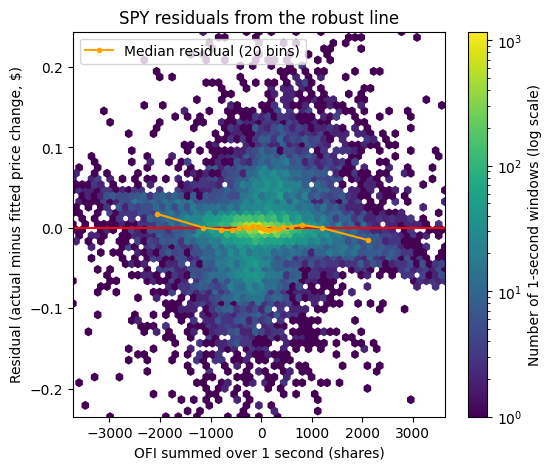

In [21]:
resid = y2 - (s2 * x2 + i2)
print("residual percentiles [1, 25, 50, 75, 99]:", np.percentile(resid, [1, 25, 50, 75, 99]))

lr, hr = np.percentile(resid, [0.5, 99.5])
fig, ax = plt.subplots(figsize=(6, 5))
hb = ax.hexbin(x2, resid, gridsize=60, bins="log", extent=(lx, hx, lr, hr), mincnt=1)
fig.colorbar(hb, label="Number of 1-second windows (log scale)")
ax.axhline(0, color="red", lw=1.5)

edges = np.quantile(x2, np.linspace(0, 1, 21))
b = np.digitize(x2, edges[1:-1])
ks = [k for k in range(20) if (b == k).any()]
ax.plot([np.median(x2[b == k]) for k in ks], [np.median(resid[b == k]) for k in ks],
        color="orange", marker="o", ms=3, label="Median residual (20 bins)")

ax.set_xlim(lx, hx); ax.set_ylim(lr, hr)
ax.set_xlabel("OFI summed over 1 second (shares)")
ax.set_ylabel("Residual (actual minus fitted price change, $)")
ax.set_title("SPY residuals from the robust line")
ax.legend(loc="upper left")
fig.savefig(ROOT / "figures" / "03_spy_ofi_residuals_1s.png", dpi=150, bbox_inches="tight")
plt.show()